<a href="https://colab.research.google.com/github/BarGinger/Deep_Learning_MEG/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning - Assigment 2

### Group Number: 22

### Teammates:
1. **Mahshid Jafar Tajrishi**
2. **Bar Melinarskiy**
3. **Cis van Aken**
4. **Simon van Klompenburg**

## Imports entire notebook

In [5]:
# Helper function to check if the code is running in Google Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Usage
if is_colab():
    print("Running in Google Colab")
else:
    print("Not running in Google Colab")


# Importing libraries
import pandas as pd
import numpy as np
import Models
import utils as utils
import torch
import matplotlib.pyplot as plt
import os
import random
import datetime
import importlib
importlib.reload(utils)
importlib.reload(Models)
from Model import MEGClassifier, TinyMLP

Not running in Google Colab


## Global Definitions

In [6]:
# Path to the zip file
data_dir = "./Data"
google_drive_folder = "/content/drive/MyDrive/UU"
zip_path = f"{data_dir}/Final Project data.zip"
output_dir = "./Output"
model_dir = "./Models"

# check if outpiut directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# check if model directory exists
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Set the device to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

debug_mode = False

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# model and data related parameters
scaler_type = utils.NormalizationType.Z_SCORE_LOCAL  # or MINMAX_LOCAL, Z_SCORE_TIMEWISE
which_dataset = "intra"  # or "cross"
downsample = True  # or False
downsample_rate = 0  
if downsample:
    downsample_rate = 9

### Check if we are in google colab then we need to mount the drive

In [7]:
# If we are in colab and we need to mount the drive
if is_colab():
  from google.colab import drive
  # Mount Google Drive
  drive.mount('/content/drive')
  print("Google Drive mounted successfully.")
  data_dir = f"{google_drive_folder}/Final Project data"
else:
  print("Not in Google Colab.")

Not in Google Colab.


### Check if we have cude

In [8]:
# Check if CUDA is available
print(torch.__version__)
print(torch.version.cuda)  # Should match CUDA 12.5
print(torch.backends.cudnn.version())  # Should return a version, not None
print(torch.cuda.is_available())  # Should return True

2.7.0+cu126
12.6
90701
True


### Extract the Zip File

In [9]:
import zipfile

# Check if the dataset is already extracted, if not extract it
if not os.path.exists(data_dir):
    print("Extracting the dataset...")
    #unzip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    #list files in the extracted dir
    os.listdir(data_dir)
else:
    print("Dataset already extracted.")

Dataset already extracted.


### Load one example

Matrix shape: (248, 35624)


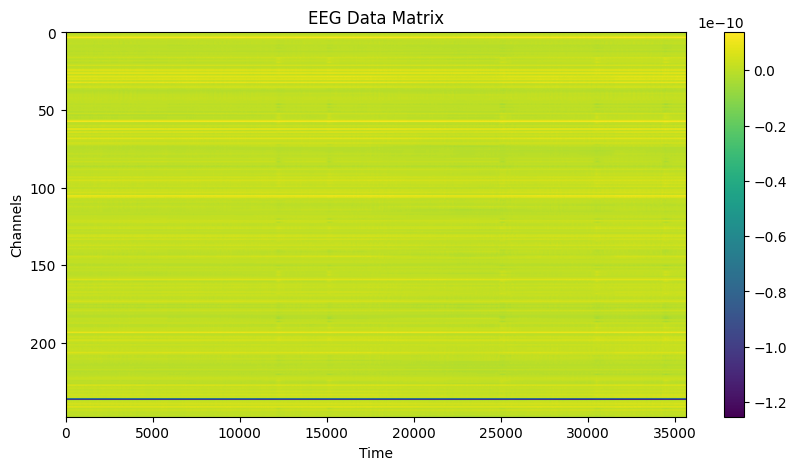

In [10]:
## peak into a matrix to see the data
matrix = utils.get_dataset_from_h5py(f"{data_dir}/Intra/train/task_working_memory_105923_3.h5")
if matrix is not None:
    print(f"Matrix shape: {matrix.shape}")


# plot that matrix
plt.figure(figsize=(10, 5))
plt.imshow(matrix, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("EEG Data Matrix")
plt.xlabel("Time")
plt.ylabel("Channels")
plt.show()

### Load the datasets

In [11]:
## load the chosen dataset/s
print(f"Loading {which_dataset} dataset...")
if which_dataset == "intra":
    # INTRA TRAIN
    intra_train_data_scaled, intra_train_df = utils.try_load_scaled("intra_train", scaler_type)
    if intra_train_data_scaled is None:
        intra_train_folder = os.path.join(data_dir, "Intra", "train")
        intra_train_data, intra_train_df = utils.load_eeg_data_and_metadata(intra_train_folder, split="train")
        intra_train_data_scaled, intra_train_df = utils.scale_and_cache(
            intra_train_data, intra_train_df, "intra_train", scaler_type, downsample_factor=downsample_rate)

    # INTRA TEST
    intra_test_data_scaled, intra_test_df = utils.try_load_scaled("intra_test", scaler_type)
    if intra_test_data_scaled is None:
        intra_test_folder = os.path.join(data_dir, "Intra", "test")
        intra_test_data, intra_test_df = utils.load_eeg_data_and_metadata(intra_test_folder, split="test")
        intra_test_data_scaled, intra_test_df = utils.scale_and_cache(
            intra_test_data, intra_test_df, "intra_test", scaler_type, downsample_factor=downsample_rate)
        
if which_dataset == "cross":
    # CROSS TRAIN
    cross_train_data_scaled, cross_train_df = utils.try_load_scaled("cross_train", scaler_type)
    if cross_train_data_scaled is None:
        cross_train_folder = os.path.join(data_dir, "Cross", "train")
        cross_train_data, cross_train_df = utils.load_eeg_data_and_metadata(cross_train_folder, split="train")
        cross_train_data_scaled, cross_train_df = utils.scale_and_cache(
            cross_train_data, cross_train_df, "cross_train", scaler_type, downsample_factor=downsample_rate)

    # CROSS TEST (list of datasets)
    cross_test_data_scaled = []
    cross_test_df_list = []
    for i in range(1, 4):
        prefix = f"cross_test{i}"
        scaled, meta = utils.try_load_scaled(prefix, scaler_type)
        if scaled is None:
            folder = os.path.join(data_dir, "Cross", f"test{i}")
            data, df = utils.load_eeg_data_and_metadata(folder, split=f"test{i}")
            scaled, meta = utils.scale_and_cache(data, df, prefix, scaler_type, downsample_factor=downsample_rate)
        cross_test_data_scaled.append(scaled)
        cross_test_df_list.append(meta)

print(f"Data for dataset {which_dataset} was loaded successfully")

Loading intra dataset...
Scaling and saving: Data\Normalized\z_score_local\intra_train_scaled.pt
Scaling and saving: Data\Normalized\z_score_local\intra_test_scaled.pt
Data for dataset intra was loaded successfully


### Definitions for training and logging

In [12]:
# Choose which dataset to train on:
if which_dataset == "intra":
    train_data, train_df = intra_train_data_scaled, intra_train_df
    test_data, test_df = intra_test_data_scaled, intra_test_df
else: # cross
    train_data, train_df = cross_train_data_scaled, cross_train_df
    test_data, test_df = cross_test_data_scaled, cross_test_df_list

print("train task types counts:")
print(np.bincount(train_df['task_type'].astype('category').cat.codes))
print("test task types counts:")
print(np.bincount(test_df['task_type'].astype('category').cat.codes))


timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
MODEL_NAME = "TinyMLP"
model_name = f"{MODEL_NAME}_{which_dataset}"
model_pth_path = f"{model_dir}/best_model_{model_name}_{timestamp}.pth"
model_csv_path = f"{output_dir}/best_model_{model_name}_{timestamp}.csv"
model_json_path = f"{model_dir}/best_model_{model_name}_{timestamp}.json"
best_model = None

train task types counts:
[8 8 8 8]
test task types counts:
[2 2 2 2]


### Train

[I 2025-05-21 11:15:24,599] A new study created in memory with name: no-name-28233fd0-3fcb-47f9-93c7-8f769547e97f


train task types counts:
[6 7 6 6]
val task types counts:
[2 1 2 2]


Trial: 1:   0%|          | 0/25 [00:00<?, ?epoch/s]

Early stopping triggered after 11 epochs.


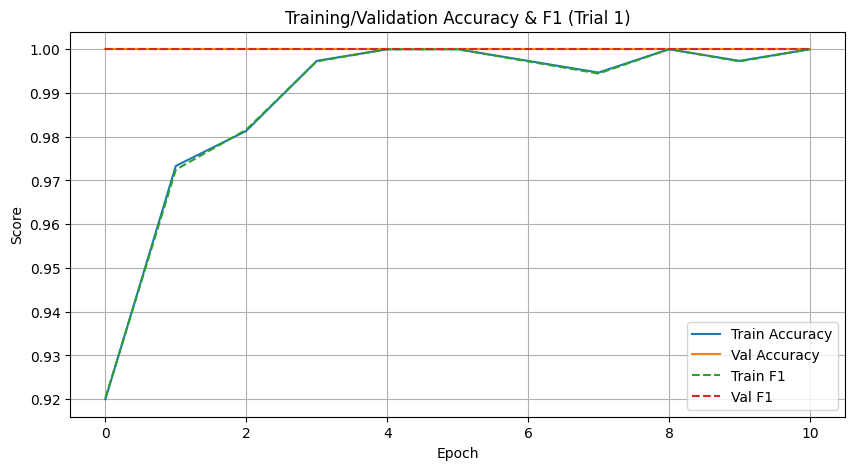

[I 2025-05-21 11:15:31,244] Trial 0 finished with value: 1.0 and parameters: {'num_temporal_filters': 16, 'temporal_kernel_size': 32, 'dropout_rate': 0.7, 'activation': 'relu', 'pool_size': 2, 'conv2d_channels': '64_128', 'transformer_d_model': 128, 'transformer_nhead': 4, 'transformer_dim_feedforward': 256, 'transformer_layers': 1, 'fc_hidden': 128, 'fc_dropout': 0.5, 'learning_rate': 0.00014569924180685102, 'batch_size': 32, 'input_time_length': 256, 'stride': 256}. Best is trial 0 with value: 1.0.


train task types counts:
[6 7 6 6]
val task types counts:
[2 1 2 2]


Trial: 2:   0%|          | 0/25 [00:00<?, ?epoch/s]

Early stopping triggered after 11 epochs.


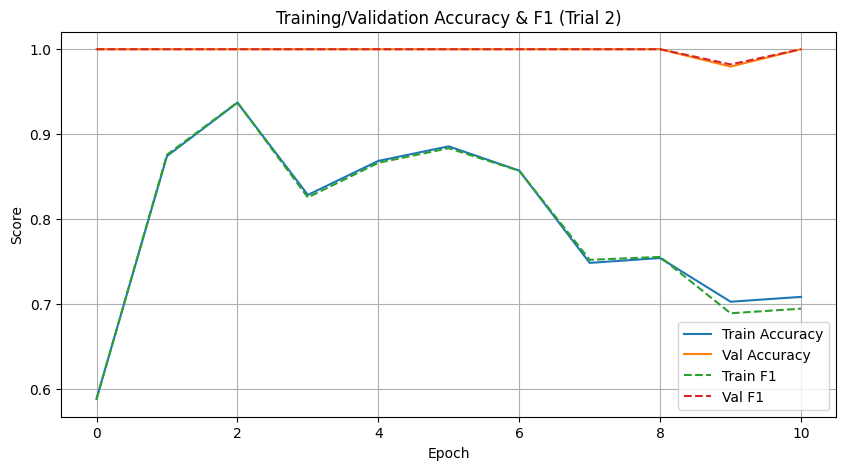

[I 2025-05-21 11:15:33,335] Trial 1 finished with value: 1.0 and parameters: {'num_temporal_filters': 16, 'temporal_kernel_size': 32, 'dropout_rate': 0.6, 'activation': 'gelu', 'pool_size': 2, 'conv2d_channels': '64_128', 'transformer_d_model': 128, 'transformer_nhead': 4, 'transformer_dim_feedforward': 256, 'transformer_layers': 1, 'fc_hidden': 128, 'fc_dropout': 0.8, 'learning_rate': 0.002309338522204442, 'batch_size': 64, 'input_time_length': 512, 'stride': 512}. Best is trial 0 with value: 1.0.


train task types counts:
[6 7 6 6]
val task types counts:
[2 1 2 2]


Trial: 3:   0%|          | 0/25 [00:00<?, ?epoch/s]

Early stopping triggered after 11 epochs.


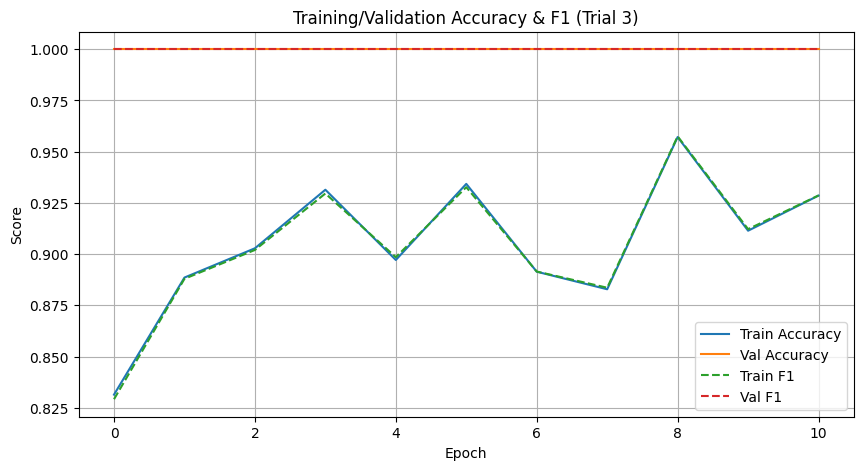

[I 2025-05-21 11:15:36,217] Trial 2 finished with value: 1.0 and parameters: {'num_temporal_filters': 8, 'temporal_kernel_size': 64, 'dropout_rate': 0.8, 'activation': 'gelu', 'pool_size': 4, 'conv2d_channels': '64_128', 'transformer_d_model': 128, 'transformer_nhead': 4, 'transformer_dim_feedforward': 256, 'transformer_layers': 1, 'fc_hidden': 64, 'fc_dropout': 0.7, 'learning_rate': 0.00019114182080836044, 'batch_size': 32, 'input_time_length': 512, 'stride': 256}. Best is trial 0 with value: 1.0.


Best model saved to ./Models/best_model_TinyMLP_intra_20250521_111524.pth
Best hyperparameters saved to ./Models/best_model_TinyMLP_intra_20250521_111524.json


In [ ]:
import optuna
import json

number_of_trials = 3

# Prepare a global DataFrame for metrics
all_metrics_df = utils.create_metrics_df()

# Define a wrapper so Optuna only gets the accuracy
def optuna_objective(trial):
    global all_metrics_df
    best_val_acc, updated_metrics_df = utils.objective(
        trial, all_metrics_df, train_data, train_df, device
    )
    all_metrics_df = updated_metrics_df  # update global after each trial
    return best_val_acc  # maximize accuracy

# Run Optuna and save best model after all trials
study = optuna.create_study(direction="maximize")
study.optimize(optuna_objective, n_trials=number_of_trials)

# Save best model after all trials
best_trial = study.best_trial
best_params = best_trial.params
best_params["input_channels"] = train_data.shape[1]
best_params["num_classes"] = len(np.unique(train_df['task_type']))

# Create the model with the best hyperparameters
best_model = MEGClassifier(**{k: v for k, v in best_params.items() if k in MEGClassifier.__init__.__code__.co_varnames}).to(device)
# best_model = TinyMLP(**{k: v for k, v in best_params.items() if k in TinyMLP.__init__.__code__.co_varnames}).to(device)
torch.save(best_model.state_dict(), model_pth_path)
print(f"Best model saved to {model_pth_path}")

# Save the best hyperparameters to a JSON file
with open(model_json_path, "w") as json_file:
    json.dump(best_params, json_file, indent=4)
print(f"Best hyperparameters saved to {model_json_path}")

### Evulate model and save logs

In [14]:
# evulate the best model on the test set
test_metrics = utils.evaluate_model_on_testset(
    best_model, test_data, test_df, device,
    batch_size=best_params.get("batch_size", 64),
    input_time_length=best_params.get("input_time_length", 256),
    stride=best_params.get("stride", 256)
)

print("Test metrics:", test_metrics, "Best trial ID:", best_trial.number, '\n')

# Add "test_" prefix to all columns in test_metrics
test_metrics_prefixed = {f"test_{k}": v for k, v in test_metrics.items()}

# Find the row for the best trial (trial_id matches best_trial.number + 1)
row_idx = all_metrics_df[all_metrics_df["trial_id"] == best_trial.number + 1].index
if len(row_idx) == 0:
    # fallback: use last row
    row_idx = [all_metrics_df.index[-1]]
row_idx = row_idx[0]

# Copy all columns in test_metrics_prefixed to the DataFrame row
for col, value in test_metrics_prefixed.items():
    if col in all_metrics_df.columns:
        all_metrics_df.at[row_idx, col] = value
            
# Save metrics
all_metrics_df.to_csv(model_csv_path, index=False)
print(f"All metrics saved to {model_csv_path}")
print("Best hyperparameters:", best_params)
print("Best validation accuracy:", study.best_value)

Test metrics: {'overall_accuracy': 0.25, 'overall_F1': 0.1, 'overall_recall': 0.25, 'overall_precision': 0.0625, 'resting_accuracy': 0.0, 'resting_F1': 0.0, 'resting_recall': 0.0, 'resting_precision': 0.0, 'math_accuracy': 0.0, 'math_F1': 0.0, 'math_recall': 0.0, 'math_precision': 0.0, 'memory_accuracy': 0.0, 'memory_F1': 0.0, 'memory_recall': 0.0, 'memory_precision': 0.0, 'motor_accuracy': 1.0, 'motor_F1': 1.0, 'motor_recall': 1.0, 'motor_precision': 1.0} Best trial ID: 0 

All metrics saved to ./Output/best_model_TinyMLP_intra_20250521_111524.csv
Best hyperparameters: {'num_temporal_filters': 16, 'temporal_kernel_size': 32, 'dropout_rate': 0.7, 'activation': 'relu', 'pool_size': 2, 'conv2d_channels': '64_128', 'transformer_d_model': 128, 'transformer_nhead': 4, 'transformer_dim_feedforward': 256, 'transformer_layers': 1, 'fc_hidden': 128, 'fc_dropout': 0.5, 'learning_rate': 0.00014569924180685102, 'batch_size': 32, 'input_time_length': 256, 'stride': 256, 'input_channels': 248, 'num_

In [15]:
from IPython.display import display, HTML

# Show the DataFrame in a scrollable box (adjust height as needed)
display(HTML(all_metrics_df.to_html(max_rows=1000, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))

,trial_id,epoch,train_overall_accuracy,train_overall_F1,train_overall_recall,train_overall_precision,train_resting_accuracy,train_resting_F1,train_resting_recall,train_resting_precision,train_math_accuracy,train_math_F1,train_math_recall,train_math_precision,train_memory_accuracy,train_memory_F1,train_memory_recall,train_memory_precision,train_motor_accuracy,train_motor_F1,train_motor_recall,train_motor_precision,val_overall_accuracy,val_overall_F1,val_overall_recall,val_overall_precision,val_resting_accuracy,val_resting_F1,val_resting_recall,val_resting_precision,val_math_accuracy,val_math_F1,val_math_recall,val_math_precision,val_memory_accuracy,val_memory_F1,val_memory_recall,val_memory_precision,val_motor_accuracy,val_motor_F1,val_motor_recall,val_motor_precision,test_overall_accuracy,test_overall_F1,test_overall_recall,test_overall_precision,test_resting_accuracy,test_resting_F1,test_resting_recall,test_resting_precision,test_math_accuracy,test_math_F1,test_math_recall,test_math_precision,test_memory_accuracy,test_memory_F1,test_memory_recall,test_memory_precision,test_motor_accuracy,test_motor_F1,test_motor_recall,test_motor_precision,input_channels,num_temporal_filters,temporal_kernel_size,dropout_rate,activation,pool_size,num_classes,conv2d_channels,transformer_d_model,transformer_nhead,transformer_dim_feedforward,transformer_layers,fc_hidden,fc_dropout,learning_rate,batch_size,input_time_length,stride
0,1,1,0.920000,0.920286,0.921643,0.920238,0.885417,0.234807,0.221354,0.250000,0.923077,0.240000,0.230769,0.250000,0.975904,0.329268,0.325301,0.333333,0.902174,0.237143,0.225543,0.250000,1.000000,1.00000,1.000000,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,0.25,0.1,0.25,0.0625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,248,16,32,0.7,relu,2,4,64_128,128,4,256,1,128,0.5,0.000146,32,256,256
1,1,2,0.973333,0.972469,0.973737,0.972222,0.987952,0.496970,0.493976,0.500000,0.972222,0.328638,0.324074,0.333333,0.967033,0.491620,0.483516,0.500000,0.967742,0.491803,0.483871,0.500000,1.000000,1.00000,1.000000,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,248,16,32,0.7,relu,2,4,64_128,128,4,256,1,128,0.5,0.000146,32,256,256
2,1,3,0.981333,0.981608,0.983038,0.980952,1.000000,1.000000,1.000000,1.000000,0.954128,0.488263,0.477064,0.500000,0.989011,0.497238,0.494505,0.500000,0.989011,0.497238,0.494505,0.500000,1.000000,1.00000,1.000000,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,248,16,32,0.7,relu,2,4,64_128,128,4,256,1,128,0.5,0.000146,32,256,256
3,1,4,0.997333,0.997222,0.997253,0.997222,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.989011,0.497238,0.494505,0.500000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,248,16,32,0.7,relu,2,4,64_128,128,4,256,1,128,0.5,0.000146,32,256,256
4,1,5,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,248,16,32,0.7,relu,2,4,64_128,128,4,256,1,128,0.5,0.000146,32,256,256
5,1,6,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,NaN,NaN,NaN

### Plot plots

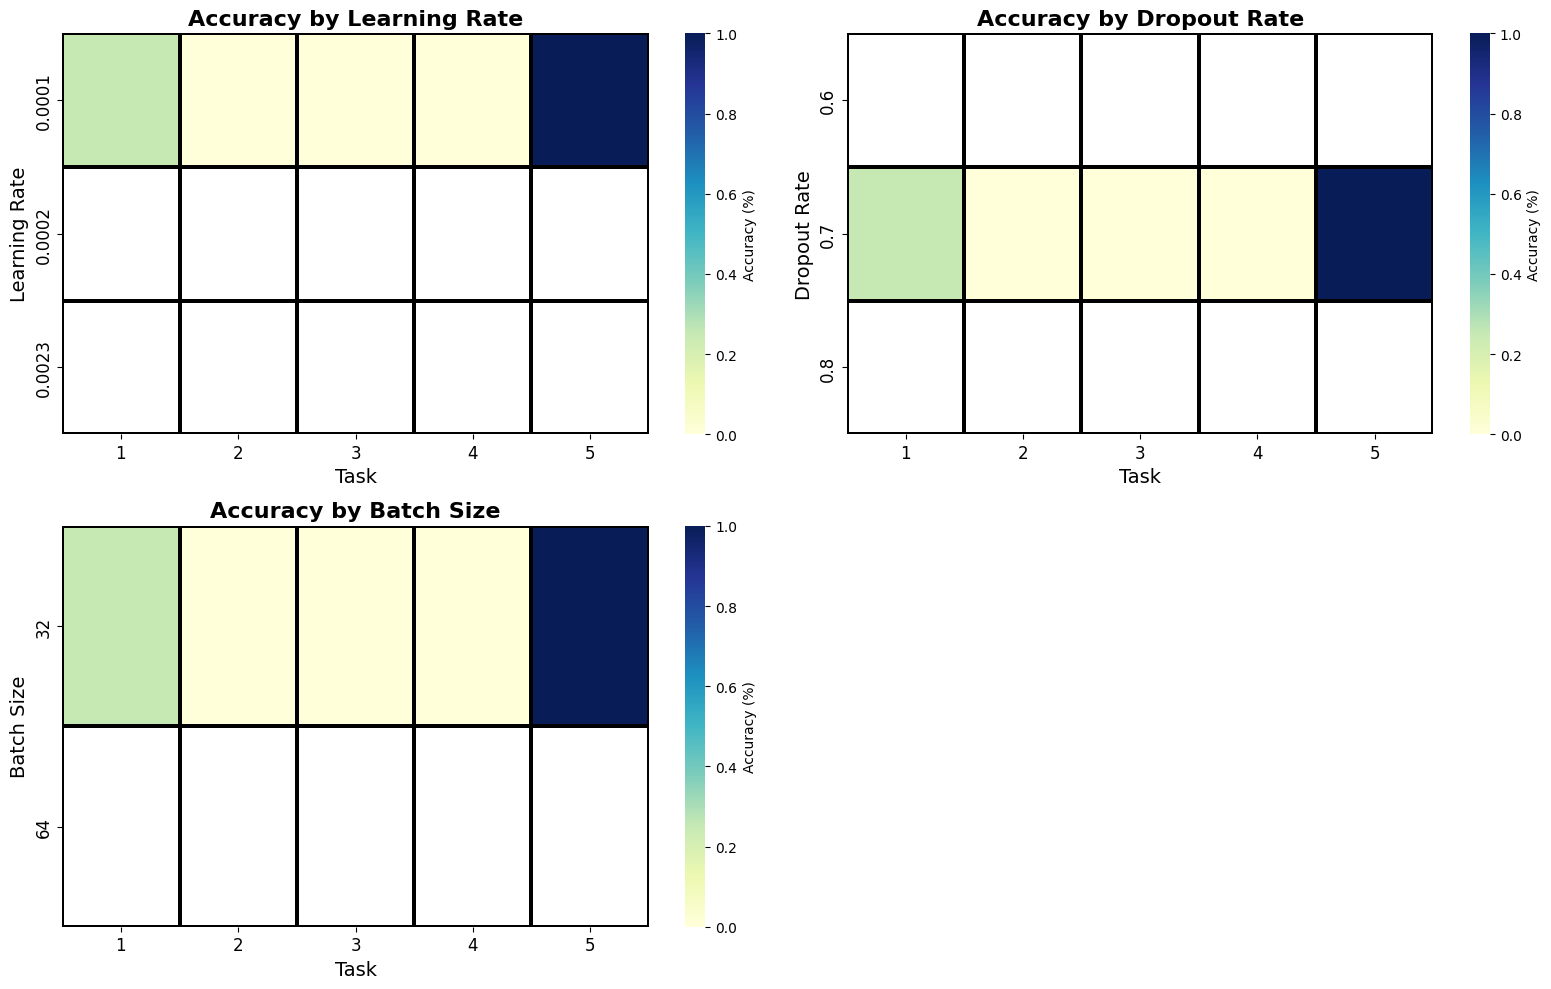

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_accuracy_heatmaps_by_parameters(df, parameters, metric="accuracy", cmap="YlGnBu"):
    ncols = 2
    nrows = (len(parameters) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 5 * nrows), facecolor='white')
    axes = axes.flatten()

    for i, param in enumerate(parameters):
        ax = axes[i]
        ax.set_facecolor('white')  # Set axes background to white

        if df[param].dtype == "float64":
            df[param] = df[param].round(4)

        task_cols = [col for col in df.columns if col.startswith("test_") and col.endswith(f"_{metric}")]
        if not task_cols:
            ax.set_title(f"No test {metric} columns found", color='red')
            ax.axis("off")
            continue

        grouped = df[[param] + task_cols].groupby(param).mean()
        renamed = grouped.rename(columns={col: str(i+1) for i, col in enumerate(grouped.columns)})
        renamed = renamed.apply(pd.to_numeric, errors='coerce')

        sns.heatmap(
            renamed,
            ax=ax,
            cmap=cmap,
            cbar=True,
            linewidths=1.5,
            linecolor="black",  # Black grid lines for visibility
            cbar_kws={"label": f"{metric.capitalize()} (%)"}
        )

        ax.set_title(f"Accuracy by {param.replace('_', ' ').title()}", fontsize=16, weight='bold', color='black')
        ax.set_xlabel("Task", fontsize=14, color='black')
        ax.set_ylabel(param.replace("_", " ").title(), fontsize=14, color='black')
        ax.tick_params(axis='both', labelsize=12, colors='black')

    for j in range(len(parameters), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

parameters_to_plot = ["learning_rate", "dropout_rate", "batch_size"]
renamed = all_metrics_df.apply(pd.to_numeric, errors='coerce')
plot_accuracy_heatmaps_by_parameters(renamed, parameters_to_plot, metric="accuracy")

In [17]:
print("we are done, goodbye")

we are done, goodbye
